# 05 Evaluation and interpretation

Reads the test-season predictions written by notebook 04 and produces the evaluation figures and
the error analysis: precision-recall curves and reliability diagrams, the alert-budget trade-off,
SHAP and permutation importance for the best model, errors per region, belt, hazard and month,
the case study of 26 to 28 September 2024, and sensitivity checks. No main model is refitted here;
the test seasons were scored once in notebook 04.

- **Inputs:** `data/processed/predictions.parquet` and `data/processed/models/stage2-models.joblib`
  (run notebook 04 first), `feature-matrix.parquet`, `hydromet-incidents.parquet`
- **Outputs:** `results/reliability-best-model.csv`, `errors-per-*.csv`, `shap-mean-abs.csv`,
  `permutation-importance.csv`, `case-study-*.csv`, `ablation-paired.csv`, `model-gaps-paired.csv`,
  `alert-*.csv`, `year-control-history.csv`; figures `fig-pr-reliability-budget`,
  `fig-errors-region-hazard-month`, `fig-shap-permutation` and `fig-case-study-2024-09`
- **Runtime:** about 10 to 25 minutes, mostly SHAP and permutation importance

## Setup

In [1]:
import sys
import time
from pathlib import Path

# Make `src` importable whether the notebook runs from notebooks/ or the repository root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from matplotlib.colors import PowerNorm
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, precision_recall_curve

from src import config as C
from src import evaluate as E
from src import features as Fe
from src import models as M
from src import plotting as PL
from src import sensitivity as S

PL.setup()
T_START = time.time()
pred = pd.read_parquet(C.PROCESSED / "predictions.parquet")
store = joblib.load(C.PROCESSED / "models" / "stage2-models.joblib")
BEST = store["best"]
F = pd.read_parquet(C.PROCESSED / "feature-matrix.parquet")
te = pred[pred["split"] == "test"].reset_index(drop=True)
y = te["y"].to_numpy()
clim = te["clim"].to_numpy()


def score(m, fs="A"):
    """Raw test score of model m with feature set fs."""
    return te[f"score_{m}_{fs}"].to_numpy()


def prob(m, fs="A"):
    """Calibrated test probability of model m with feature set fs."""
    return te[f"prob_{m}_{fs}"].to_numpy()


MODELS = ["lr", "rf", "hgb", "svm_linear", "svm_rbf"]
print(f"best model: {BEST} ({M.NAMES[BEST]}); test rows {len(te):,}, positives {int(y.sum()):,}")

best model: rf (Random forest); test rows 32,494, positives 2,749


## 1. Precision-recall curves and reliability diagrams (test 2024 to 2025)

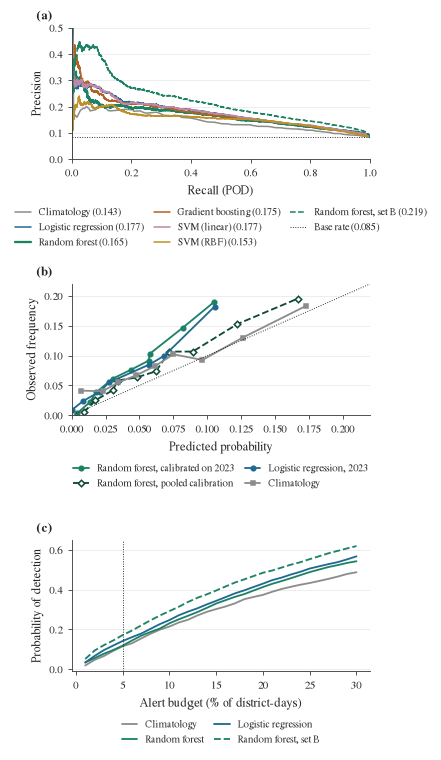

mean predicted probability: 2023 calibration 0.0467, pooled 0.0675, observed 0.0846


In [2]:
f, axes = PL.fig(width=PL.COL_W, height=7.6, nrows=3)
f.subplots_adjust(hspace=0.95)
ax = axes[0]
for m in ["climatology"] + MODELS:
    s = clim if m == "climatology" else score(m)
    p, r, _ = precision_recall_curve(y, s)
    ax.plot(
        r,
        p,
        color=PL.MODEL_COL[m],
        lw=1.0 if m != BEST else 1.5,
        label=f"{PL.MODEL_NAME[m]} ({average_precision_score(y, s):.3f})",
    )
p, r, _ = precision_recall_curve(y, score(BEST, "B"))
ax.plot(
    r,
    p,
    color=PL.MODEL_COL[BEST],
    ls="--",
    lw=1.0,
    label=f"{PL.MODEL_NAME[BEST]}, set B ({average_precision_score(y, score(BEST, 'B')):.3f})",
)
ax.axhline(y.mean(), color="k", lw=0.6, ls=":", label=f"Base rate ({y.mean():.3f})")
ax.set_xlabel("Recall (POD)")
ax.set_ylabel("Precision")
ax.set_ylim(0, 0.5)
ax.set_xlim(0, 1)
ax.legend(
    fontsize=6.5,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.3),
    ncol=3,
    columnspacing=1.0,
    handlelength=1.6,
)
PL.letter(ax, "a")

ax = axes[1]
# The two random forest lines differ in tone, dash and marker so they stay apart in grey print.
for lab, pcol, col, ls, mk, mfc in (
    (
        f"{PL.MODEL_NAME[BEST]}, calibrated on 2023",
        f"prob_{BEST}_A",
        PL.MODEL_COL[BEST],
        "-",
        "o",
        None,
    ),
    (
        f"{PL.MODEL_NAME[BEST]}, pooled calibration",
        f"prob_{BEST}_A_pooledcal",
        PL.shade(PL.MODEL_COL[BEST]),
        "--",
        "D",
        "white",
    ),
    ("Logistic regression, 2023", "prob_lr_A", PL.MODEL_COL["lr"], "-", "o", None),
):
    t = E.reliability_table(y, te[pcol].to_numpy(), bins=10)
    ax.plot(
        t["predicted"],
        t["observed"],
        marker=mk,
        ms=3,
        mfc=mfc,
        color=col,
        ls=ls,
        label=lab,
    )
t = E.reliability_table(y, clim, bins=10)
ax.plot(
    t["predicted"],
    t["observed"],
    marker="s",
    ms=3,
    color=PL.MODEL_COL["climatology"],
    label="Climatology",
)
lim = 0.22
ax.plot([0, lim], [0, lim], color="k", lw=0.6, ls=":")
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
ax.set_xlabel("Predicted probability")
ax.set_ylabel("Observed frequency")
ax.legend(
    fontsize=6.5,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.3),
    ncol=2,
    columnspacing=1.0,
    handlelength=1.6,
)
PL.letter(ax, "b")

ax = axes[2]
budgets = np.linspace(0.01, 0.30, 30)
for m in ["climatology", BEST, "lr"]:
    s = clim if m == "climatology" else score(m)
    ax.plot(
        100 * budgets,
        [E.alert_metrics(y, s, b)["pod"] for b in budgets],
        color=PL.MODEL_COL[m],
        label=PL.MODEL_NAME[m],
    )
s = score(BEST, "B")
ax.plot(
    100 * budgets,
    [E.alert_metrics(y, s, b)["pod"] for b in budgets],
    color=PL.MODEL_COL[BEST],
    ls="--",
    label=f"{PL.MODEL_NAME[BEST]}, set B",
)
ax.axvline(100 * C.ALERT_BUDGET, color="k", lw=0.6, ls=":")
ax.set_xlabel("Alert budget (% of district-days)")
ax.set_ylabel("Probability of detection")
ax.legend(
    fontsize=6.5,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.3),
    ncol=2,
    columnspacing=1.0,
    handlelength=1.6,
)
PL.letter(ax, "c")
PL.save(f, "fig-pr-reliability-budget")
rel = E.reliability_table(y, prob(BEST), bins=10)
rel["model"] = f"{BEST}_A_2023cal"
rel2 = E.reliability_table(y, te[f"prob_{BEST}_A_pooledcal"].to_numpy(), bins=10)
rel2["model"] = f"{BEST}_A_pooledcal"
pd.concat([rel, rel2]).round(4).to_csv(C.RESULTS / "reliability-best-model.csv", index=False)
print(
    "mean predicted probability: 2023 calibration %.4f, pooled %.4f, observed %.4f"
    % (prob(BEST).mean(), te[f"prob_{BEST}_A_pooledcal"].mean(), y.mean())
)

## 2. Errors per region, belt, hazard and month (best model, set A)

Per region and belt: PR-AUC of the model and of climatology, and POD at the national 5% budget
(alerts are allocated nationally, so a region's POD shows whether it gets its share). Per hazard:
how well the pooled score ranks each hazard's own label. Per month: the same against the month's
base rate.

In [3]:
s_best, p_best = score(BEST), prob(BEST)
k = int(round(C.ALERT_BUDGET * len(te)))
alert = np.zeros(len(te), bool)
alert[np.argsort(-s_best, kind="stable")[:k]] = True


def strata(col, order=None):
    rows = []
    for g, d in te.groupby(col):
        i = d.index.to_numpy()
        if y[i].sum() < 5:
            continue
        met = E.metrics(y[i], s_best[i], clim[i], p_best[i], alert=alert[i])
        rows.append(
            {
                col: g,
                "rows": len(i),
                "positives": int(y[i].sum()),
                "base_rate": y[i].mean(),
                "clim_pr_auc": average_precision_score(y[i], clim[i]),
                "pr_auc": met["pr_auc"],
                "bss": met["bss"],
                "pod_at_national_budget": met["pod"],
                "far": met["far"],
                "alert_share": alert[i].mean(),
            }
        )
    out = pd.DataFrame(rows).set_index(col)
    return out.reindex(order) if order else out


by_region = strata("region")
by_belt = strata("belt", ["Terai", "Hill", "Mountain"])
by_month = strata("month")
by_region.round(4).to_csv(C.RESULTS / "errors-per-region.csv")
by_belt.round(4).to_csv(C.RESULTS / "errors-per-belt.csv")
by_month.round(4).to_csv(C.RESULTS / "errors-per-month.csv")
rows = []
for h in C.HAZARDS.values():
    yh = te[f"y_{h}"].to_numpy()
    rows.append(
        {
            "hazard": h,
            "positives": int(yh.sum()),
            "base_rate": yh.mean(),
            "pr_auc_pooled_score": average_precision_score(yh, s_best),
            "pr_auc_climatology": average_precision_score(yh, clim),
            "pr_auc_set_b": average_precision_score(yh, score(BEST, "B")),
            "pod_at_national_budget": (alert & (yh == 1)).sum() / yh.sum(),
        }
    )
by_hazard = pd.DataFrame(rows).set_index("hazard")
by_hazard.round(4).to_csv(C.RESULTS / "errors-per-hazard.csv")
print("by region:\n", by_region.round(3).to_string())
print("\nby belt:\n", by_belt.round(3).to_string())
print("\nby hazard:\n", by_hazard.round(3).to_string())
print("\nby month:\n", by_month.round(3).to_string())

by region:
         rows  positives  base_rate  clim_pr_auc  pr_auc    bss  pod_at_national_budget    far  alert_share
region                                                                                                    
0       3798        350      0.092        0.145   0.162  0.007                   0.160  0.829        0.086
1       2532        271      0.107        0.173   0.151 -0.034                   0.037  0.865        0.029
2       5064        353      0.070        0.166   0.206 -0.010                   0.218  0.734        0.057
3       8440        756      0.090        0.183   0.196 -0.013                   0.093  0.745        0.032
4       9706        735      0.076        0.109   0.139  0.011                   0.095  0.815        0.039
5       2954        284      0.096        0.155   0.154 -0.019                   0.151  0.846        0.095

by belt:
            rows  positives  base_rate  clim_pr_auc  pr_auc    bss  pod_at_national_budget    far  alert_share
belt       

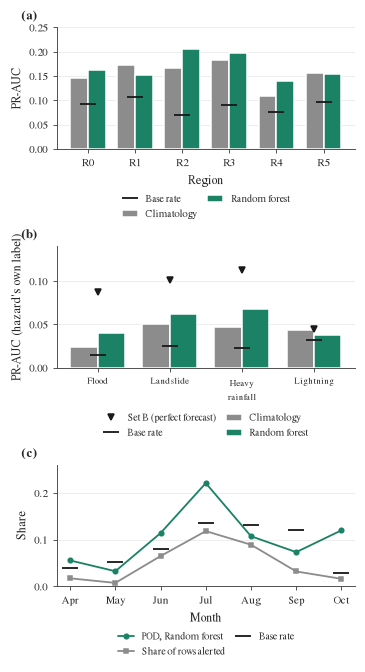

In [4]:
f, axes = PL.fig(width=PL.COL_W, height=6.6, nrows=3)
f.subplots_adjust(hspace=0.8)
ax = axes[0]
x = np.arange(len(by_region))
w = 0.38
ax.bar(
    x - w / 2, by_region["clim_pr_auc"], w, color=PL.MODEL_COL["climatology"], label="Climatology"
)
ax.bar(x + w / 2, by_region["pr_auc"], w, color=PL.MODEL_COL[BEST], label=PL.MODEL_NAME[BEST])
ax.plot(x, by_region["base_rate"], "k_", ms=10, mew=1.2, label="Base rate")
ax.set_xticks(x)
ax.set_xticklabels([f"R{int(r)}" for r in by_region.index])
ax.set_ylabel("PR-AUC")
ax.set_xlabel("Region")
ax.set_ylim(0, 0.25)
ax.legend(
    fontsize=6.5,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.3),
    ncol=2,
    columnspacing=1.0,
    handlelength=1.6,
)
PL.letter(ax, "a")
ax = axes[1]
x = np.arange(4)
hz = list(C.HAZARDS.values())
ax.bar(
    x - w / 2,
    by_hazard["pr_auc_climatology"],
    w,
    color=PL.MODEL_COL["climatology"],
    label="Climatology",
)
ax.bar(
    x + w / 2,
    by_hazard["pr_auc_pooled_score"],
    w,
    color=PL.MODEL_COL[BEST],
    label=PL.MODEL_NAME[BEST],
)
ax.plot(
    x,
    by_hazard["pr_auc_set_b"],
    marker="v",
    ls="none",
    color="k",
    ms=4,
    label="Set B (perfect forecast)",
)
ax.plot(x, by_hazard["base_rate"], "k_", ms=10, mew=1.2, label="Base rate")
ax.set_xticks(x)
ax.set_xticklabels([PL.HAZARD_NAME[h].replace(" ", "\n") for h in hz], fontsize=6)
ax.set_ylabel("PR-AUC (hazard's own label)")
ax.set_ylim(0, 1.25 * by_hazard["pr_auc_set_b"].max())
ax.legend(
    fontsize=6.5,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.3),
    ncol=2,
    columnspacing=1.0,
    handlelength=1.6,
)
PL.letter(ax, "b")
ax = axes[2]
ax.plot(
    by_month.index,
    by_month["pod_at_national_budget"],
    marker="o",
    ms=3,
    color=PL.MODEL_COL[BEST],
    label=f"POD, {PL.MODEL_NAME[BEST]}",
)
ax.plot(
    by_month.index,
    by_month["alert_share"],
    marker="s",
    ms=3,
    color="#8C8C8C",
    label="Share of rows alerted",
)
ax.plot(
    by_month.index,
    by_month["base_rate"],
    marker="_",
    ls="none",
    ms=10,
    mew=1.2,
    color="k",
    label="Base rate",
)
ax.set_xticks(range(4, 11))
ax.set_xticklabels(["Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct"])
ax.set_ylabel("Share")
ax.set_xlabel("Month")
ax.set_ylim(0, 0.26)
ax.legend(
    fontsize=6.5,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.3),
    ncol=2,
    columnspacing=1.0,
    handlelength=1.6,
)
PL.letter(ax, "c")
PL.save(f, "fig-errors-region-hazard-month")

## 3. What drives the forecast: SHAP and permutation importance

SHAP values are computed on the raw score of the best model for a 4,000-row stratified sample of
the test rows (feature set A). Permutation importance (drop in PR-AUC when one feature is
shuffled, 5 repeats) is computed for the best model and for logistic regression on the same rows.

In [5]:
rng = np.random.default_rng(C.SEED)
Fte = F[F["split"] == "test"].reset_index(drop=True)
assert (Fte["date"].to_numpy() == te["date"].to_numpy()).all() and (
    Fte["district"].to_numpy() == te["district"].to_numpy()
).all()
idx = np.concatenate(
    [
        rng.choice(np.flatnonzero(y == c), size=int(round(4000 * np.mean(y == c))), replace=False)
        for c in (0, 1)
    ]
)
Xs = Fte.loc[idx, Fe.FEATURES_A]
model_A = store["model_A"].model
if BEST in ("rf", "hgb"):
    expl = shap.TreeExplainer(model_A)
    sv = expl.shap_values(Xs.to_numpy(float))
    sv = sv[1] if isinstance(sv, list) else (sv[:, :, 1] if sv.ndim == 3 else sv)
else:
    bg = shap.kmeans(
        Fte.loc[rng.choice(len(Fte), 200, replace=False), Fe.FEATURES_A].to_numpy(float), 20
    )
    sv = shap.KernelExplainer(lambda X: M.raw_score(model_A, X), bg).shap_values(
        Xs.to_numpy(float), nsamples=200
    )
shap_abs = pd.Series(np.abs(sv).mean(axis=0), index=Fe.FEATURES_A).sort_values(ascending=False)
shap_abs.rename("mean_abs_shap").to_csv(C.RESULTS / "shap-mean-abs.csv")
print("top 10 features by mean |SHAP|:\n", shap_abs.head(10).round(4).to_string())


class RawScore:
    """Expose a calibrated model's raw score as `predict`, the interface permutation_importance needs."""

    def __init__(self, calibrated):
        self.calibrated = calibrated

    def fit(self, *args):
        return self

    def predict(self, X):
        return self.calibrated.raw(X)


rows = []
for name, obj in ((BEST, store["model_A"]), ("lr", store["lr_A"])):
    pi = permutation_importance(
        RawScore(obj),
        Xs.to_numpy(float),
        y[idx],
        scoring=lambda est, X, yy: average_precision_score(yy, est.predict(X)),
        n_repeats=5,
        random_state=C.SEED,
        n_jobs=1,
    )
    rows.append(
        pd.DataFrame(
            {
                "model": name,
                "feature": Fe.FEATURES_A,
                "drop_in_pr_auc": pi.importances_mean,
                "sd": pi.importances_std,
            }
        )
    )
perm = pd.concat(rows).sort_values(["model", "drop_in_pr_auc"], ascending=[True, False])
perm.round(5).to_csv(C.RESULTS / "permutation-importance.csv", index=False)
print(
    "\npermutation importance, top 8:\n",
    perm.groupby("model").head(8).round(4).to_string(index=False),
)

top 10 features by mean |SHAP|:
 rain_3d_pct      0.0247
rain_1d          0.0228
te_dam           0.0203
doy_cos          0.0179
doy_sin          0.0178
te_lightning     0.0178
rain_7d          0.0170
rain_hours_1d    0.0166
rain_3d          0.0160
rain_14d         0.0142



permutation importance, top 8:
 model           feature  drop_in_pr_auc     sd
   lr           doy_sin          0.0351 0.0094
   lr          rain_api          0.0150 0.0036
   lr             month          0.0145 0.0095
   lr         elev_mean          0.0122 0.0041
   lr       rain_3d_pct          0.0112 0.0033
   lr     rain_hours_1d          0.0107 0.0036
   lr      te_landslide          0.0085 0.0016
   lr      te_lightning          0.0078 0.0041
   rf       rain_3d_pct          0.0076 0.0018
   rf           rain_1d          0.0064 0.0030
   rf     recent_dam_7d          0.0063 0.0007
   rf           rain_3d          0.0052 0.0014
   rf nbr_recent_dam_7d          0.0046 0.0011
   rf          te_flood          0.0034 0.0011
   rf          rain_14d          0.0030 0.0037
   rf           doy_cos          0.0025 0.0026


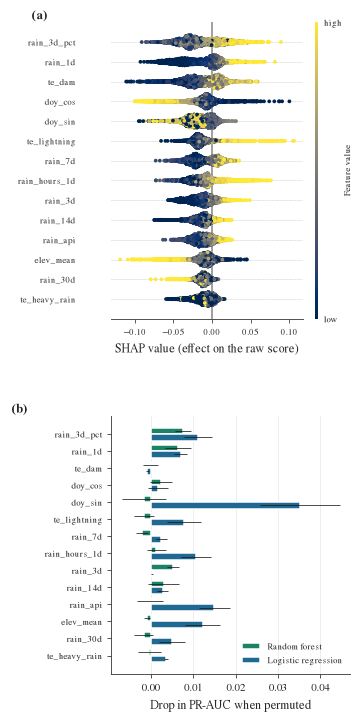

In [6]:
f, axes = PL.fig(width=PL.COL_W, height=6.4, nrows=2, gridspec_kw={"height_ratios": [1.15, 1]})
plt.sca(axes[0])
shap.summary_plot(
    sv,
    Xs,
    feature_names=Fe.FEATURES_A,
    max_display=14,
    show=False,
    plot_size=None,
    color_bar_label="Feature value",
    cmap="cividis",
)
axes[0].set_xlabel("SHAP value (effect on the raw score)", fontsize=8)
axes[0].tick_params(labelsize=6)
cbar = f.axes[-1]
cbar.set_ylabel("Feature value", fontsize=6, labelpad=1)
cbar.tick_params(labelsize=6)
cbar.set_yticks([cbar.get_ylim()[0], cbar.get_ylim()[1]])
cbar.set_yticklabels(["low", "high"])
for coll in axes[0].collections:
    coll.set_sizes([6])
PL.letter(axes[0], "a", x=-0.42, y=1.0)
ax = axes[1]
top = shap_abs.head(14).index[::-1]
pb = perm[perm["model"] == BEST].set_index("feature").reindex(top)
pl = perm[perm["model"] == "lr"].set_index("feature").reindex(top)
yy = np.arange(len(top))
h = 0.38
ax.barh(
    yy + h / 2,
    pb["drop_in_pr_auc"],
    h,
    xerr=pb["sd"],
    color=PL.MODEL_COL[BEST],
    label=PL.MODEL_NAME[BEST],
    error_kw={"lw": 0.5},
)
ax.barh(
    yy - h / 2,
    pl["drop_in_pr_auc"],
    h,
    xerr=pl["sd"],
    color=PL.MODEL_COL["lr"],
    label="Logistic regression",
    error_kw={"lw": 0.5},
)
ax.set_yticks(yy)
ax.set_yticklabels(top, fontsize=6)
ax.set_xlabel("Drop in PR-AUC when permuted")
ax.legend(fontsize=6, loc="lower right")
ax.grid(axis="x")
ax.grid(False, axis="y")
PL.letter(ax, "b", x=-0.42, y=1.0)
f.subplots_adjust(hspace=0.35, left=0.3)
PL.save(f, "fig-shap-permutation")

## 4. Case study: 26 to 28 September 2024

The forecast issued at the end of 25 September 2024 (set A: ERA5 analysis up to that day) and the
perfect-forecast version (set B) against the districts that recorded damaging incidents on 26 to
28 September, when a late-monsoon system hit central and eastern Nepal. The alert list is the
national 5% budget applied to that issue day (the top 4 districts) and, for context, the top 10.

In [7]:
ISSUE = pd.Timestamp("2024-09-25")
day = te[te["date"] == ISSUE].set_index("district")
obs = day["y"]
case = pd.DataFrame(
    {
        "prob_set_a": day[f"prob_{BEST}_A"],
        "score_set_a": day[f"score_{BEST}_A"],
        "prob_set_b": day[f"prob_{BEST}_B"],
        "score_set_b": day[f"score_{BEST}_B"],
        "climatology": day["clim"],
        "observed": obs,
    }
)
RANK = {"set A": "score_set_a", "set B": "score_set_b", "climatology": "climatology"}
for lab, col in RANK.items():
    case[f"rank_{col}"] = case[col].rank(ascending=False, method="min").astype(int)
case.sort_values("rank_score_set_a").round(3).to_csv(C.RESULTS / "case-study-2024-09-25.csv")
n_pos = int(obs.sum())
case_rows = []
for lab, col in RANK.items():
    rank_of_hits = case.loc[obs == 1, f"rank_{col}"]
    hits = {k: int((rank_of_hits <= k).sum()) for k in (4, 10, 20)}
    case_rows.append(
        {
            "ranking": lab,
            "positives": n_pos,
            **{f"hits_top{k}": v for k, v in hits.items()},
            "pr_auc_day": average_precision_score(obs, case[col]),
        }
    )
    print(
        f"{lab}: of {n_pos} districts with damage on 26 to 28 Sep, {hits[4]} are in the top 4, "
        f"{hits[10]} in the top 10 and {hits[20]} in the top 20; "
        f"PR-AUC on the day {case_rows[-1]['pr_auc_day']:.3f}"
    )
pd.DataFrame(case_rows).round(3).to_csv(C.RESULTS / "case-study-summary.csv", index=False)
print("observed districts:", ", ".join(sorted(obs[obs == 1].index)))
inc = pd.read_parquet(C.PROCESSED / "hydromet-incidents.parquet")
ev = inc[inc["damaging"] & inc["date"].between("2024-09-26", "2024-09-28")]
print(
    f"damaging incidents dated 26 to 28 Sep 2024: {len(ev)} in {ev['district'].nunique()} districts; by hazard {ev['hazard'].value_counts().to_dict()}"
)

set A: of 42 districts with damage on 26 to 28 Sep, 3 are in the top 4, 6 in the top 10 and 9 in the top 20; PR-AUC on the day 0.579
set B: of 42 districts with damage on 26 to 28 Sep, 3 are in the top 4, 8 in the top 10 and 15 in the top 20; PR-AUC on the day 0.771
climatology: of 42 districts with damage on 26 to 28 Sep, 2 are in the top 4, 4 in the top 10 and 11 in the top 20; PR-AUC on the day 0.595
observed districts: Arghakhanchi, Bara, Bhaktapur, Bhojpur, Chitwan, Dailekh, Dhading, Dhankuta, Dolakha, Gorkha, Gulmi, Ilam, Jhapa, Kathmandu, Kavrepalanchok, Khotang, Lalitpur, Mahottari, Makwanpur, Morang, Myagdi, Nuwakot, Okhaldhunga, Palpa, Panchthar, Parsa, Ramechhap, Rasuwa, Rautahat, Rukum East, Rupandehi, Sankhuwasabha, Saptari, Sarlahi, Sindhuli, Sindhupalchok, Siraha, Solukhumbu, Surkhet, Tanahu, Terhathum, Udayapur
damaging incidents dated 26 to 28 Sep 2024: 232 in 42 districts; by hazard {'landslide': 148, 'flood': 47, 'heavy_rain': 35, 'lightning': 2}


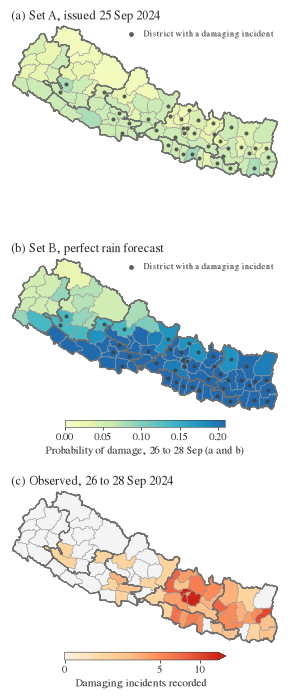

In [8]:
f, axes = PL.fig(width=PL.COL_W, height=6.0, nrows=3)
f.subplots_adjust(hspace=0.5, left=0.01, right=0.99, top=0.97, bottom=0.03)
hit_names = obs[obs == 1].index
# Panels (a) and (b) share one colour scale, capped at the 98th percentile.
vmax = float(np.percentile(np.concatenate([case["prob_set_a"], case["prob_set_b"]]), 98))
PL.choropleth(
    axes[0],
    case["prob_set_a"],
    "",
    cmap=PL.SEQ_PROB,
    vmin=0,
    vmax=vmax,
    cbar=False,
    title="(a) Set A, issued 25 Sep 2024",
)
PL.choropleth(
    axes[1],
    case["prob_set_b"],
    "Probability of damage, 26 to 28 Sep (a and b)",
    cmap=PL.SEQ_PROB,
    vmin=0,
    vmax=vmax,
    title="(b) Set B, perfect rain forecast",
)
for ax in axes[:2]:
    PL.highlight(ax, hit_names)
cnt = ev.groupby("district").size().astype(float)
PL.choropleth(
    axes[2],
    cnt,
    "Damaging incidents recorded",
    cmap=PL.SEQ_COUNT,
    norm=PowerNorm(0.5, vmin=0, vmax=float(np.percentile(cnt, 95))),
    title="(c) Observed, 26 to 28 Sep 2024",
)
PL.save(f, "fig-case-study-2024-09")

## 5. Sensitivity checks from the saved predictions

Computed from the test scores saved by notebook 04; no model is refitted.

- Paired feature-set ablation: set A minus NOWX and set B minus set A per model, and the gap
  between models within set A, each on the same weekly resamples as the main tables.
- Alerts: the 5% budget is a share of the scored test rows, pooled over the season (about four
  district alerts a day on average, not a fixed number each day). Tied scores at the cut are broken
  at random with the fixed seed. Each rule baseline is compared with climatology and the models
  re-thresholded to the rule's own alert rate. A second version fixes the threshold on 2023 scores
  (random forest and logistic regression, the two saved models).
- Year control: a history control (shrunk district by month rate and month) with and without year.

In [9]:
Fte = F[F["split"] == "test"]
assert (Fte["date"].to_numpy() == te["date"].to_numpy()).all()
assert (Fte["district"].to_numpy() == te["district"].to_numpy()).all()
ablation = S.paired_ablation(te)
ablation.to_csv(C.RESULTS / "ablation-paired.csv")
gaps = S.model_gaps(te, ref=BEST)
gaps.to_csv(C.RESULTS / "model-gaps-paired.csv")
print("paired feature-set ablation (PR-AUC):\n", ablation.round(3).to_string())
print(f"\npaired gap against {BEST}, set A:\n", gaps.round(3).to_string())

paired feature-set ablation (PR-AUC):
             pr_auc_nowx  pr_auc_a  pr_auc_b  a_minus_nowx  a_minus_nowx_lo  a_minus_nowx_hi  b_minus_a  b_minus_a_lo  b_minus_a_hi
model                                                                                                                             
lr                0.164     0.177     0.212         0.014           -0.005            0.041      0.035         0.009         0.072
rf                0.143     0.165     0.219         0.022            0.001            0.045      0.054         0.014         0.112
hgb               0.164     0.175     0.220         0.011           -0.007            0.030      0.045         0.010         0.099
svm_linear        0.164     0.177     0.211         0.013           -0.007            0.040      0.034         0.009         0.071
svm_rbf           0.141     0.153     0.179         0.012           -0.001            0.030      0.026         0.009         0.051

paired gap against rf, set A:
             

In [10]:
yo = S.year_only_score(F)
yo_ref = pd.read_csv(C.RESULTS / "test-baselines.csv", index_col=0).loc[
    "year_only_control", "pr_auc"
]
assert np.isclose(average_precision_score(y, yo), yo_ref)
budget = S.alert_budget(te, yo)
budget.to_csv(C.RESULTS / "alert-budget.csv")
rules = S.rules_at_own_rate(te, S.rule_flags(F))
rules.to_csv(C.RESULTS / "alert-rules-own-rate.csv", index=False)
thr23 = S.threshold_from_2023(F, te, store)
thr23.to_csv(C.RESULTS / "alert-threshold-2023.csv")
hist = S.history_year_control(F)
hist.to_csv(C.RESULTS / "year-control-history.csv")
print("5% budget, random tie-breaking:\n", budget.round(3).to_string())
print("\nrules at their own alert rate:\n", rules.round(3).to_string())
print("\nthreshold fixed on 2023 scores:\n", thr23.round(3).to_string())
print("\nhistory control with and without year:\n", hist.round(4).to_string())

5% budget, random tie-breaking:
                      pod    far    csi  alert_rate      n  positives
model                                                               
climatology        0.115  0.805  0.078        0.05  32494       2749
year_only_control  0.103  0.826  0.069        0.05  32494       2749
lr                 0.142  0.760  0.098        0.05  32494       2749
rf                 0.119  0.799  0.081        0.05  32494       2749
hgb                0.131  0.778  0.090        0.05  32494       2749
svm_linear         0.141  0.762  0.097        0.05  32494       2749
svm_rbf            0.120  0.796  0.082        0.05  32494       2749
lr_NOWX            0.132  0.777  0.091        0.05  32494       2749
rf_NOWX            0.104  0.825  0.070        0.05  32494       2749
hgb_NOWX           0.128  0.783  0.088        0.05  32494       2749
svm_linear_NOWX    0.130  0.781  0.089        0.05  32494       2749
svm_rbf_NOWX       0.096  0.838  0.064        0.05  32494       2749
l

In [11]:
print(f"notebook run time: {(time.time() - T_START) / 60:.1f} min")

notebook run time: 10.3 min
